In [2]:
# Plot Banzhaf distribution by n

from kernelprob.utils.p_generator import get_p

import matplotlib.pyplot as plt
import numpy as np

beta_shap_sym = {
    "shapley" : "Shapley",
    "beta_shapley_2_2" : "Beta(2,2)",
    "beta_shapley_4_4" : "Beta(4,4)",
    "beta_shapley_8_8" : "Beta(8,8)",
    "beta_shapley_16_16" : "Beta(16,16)",
}

beta_shap_asym = {
    "shapley" : "Shapley",
    "beta_shapley_1_2" : "Beta(1,2)",
    "beta_shapley_1_4" : "Beta(1,4)",
    "beta_shapley_1_8" : "Beta(1,8)",
    "beta_shapley_1_16" : "Beta(1,16)",
}


weighted_banzhaf = {
    "banzhaf" : "Banzhaf",
    "weighted_banzhaf_0.6" : "WB(0.6)",
    "weighted_banzhaf_0.7" : "WB(0.7)",
    "weighted_banzhaf_0.8" : "WB(0.8)",
    "weighted_banzhaf_0.9" : "WB(0.9)",
}


weightings = {
    "Symmetric Beta Shapley" : beta_shap_sym,
    "Asymmetric Beta Shapley" : beta_shap_asym,
    "Weighted Banzhaf" : weighted_banzhaf,
}

linestyles = ['-', '--', '-.', ':', (5, (10, 3))]
cb_colors = [
    "#E69F00",  # Orange
    "#56B4E9",  # Sky Blue
    "#009E73",  # Bluish Green
    "#0072B2",  # Blue
    "#D55E00",  # Vermillion
    "#CC79A7",  # Reddish Purple
]

def plot_probabilistic_values(n, figsize):
    # 3 plots in a row
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for plot_idx, (weightings_name, weighting_dict) in enumerate(weightings.items()):
        ax = axs[plot_idx]
        for idx, (weighting, weighting_name) in enumerate(weighting_dict.items()):
            p = get_p(n, weighting)
            ax.plot(np.arange(n), p, label=weighting_name, linestyle=linestyles[idx], color=cb_colors[idx])
        ax.set_title(weightings_name + fr" ($n={n}$)")
        ax.set_xlabel(r"$|S|$")
        if plot_idx == 0:
            ax.set_ylabel(r"$p_{|S|}$")
        ax.set_yscale('log')
        ax.legend()

    plt.tight_layout()
    plt.savefig("images/probabilistic_values.pdf", bbox_inches='tight', dpi=300)

import scipy

def compute_bn(p, n):
    valid_sizes = np.array(list(range(n+1)))

    sum1, sum2 = 0, 0
    for ell in range(n):
        sum1 += scipy.special.binom(n-1, ell) * p[ell]**2
        if ell >= 1:
            sum2 += scipy.special.binom(n-2, ell-1) * (p[ell]-p[ell-1])**2
    an = 2*sum1 - sum2
    bn = sum2 / an
    return bn

def compute_square_prob_sum(p, n):
    total = (p[0]*n)**2 + (p[-1]*n)**2
    for size in range(1, n-1):
        total += (p[size-1] * size - p[size] * (n - size))**2 * scipy.special.binom(n, size)
    return total

def plot_bn(ns, figsize, plot_sum=False):
    # 3 plots in a row
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for plot_idx, (weightings_name, weighting_dict) in enumerate(weightings.items()):
        ax = axs[plot_idx]
        for idx, (weighting, weighting_name) in enumerate(weighting_dict.items()):
            bns = []
            for n in ns:
                p = get_p(n, weighting)
                if plot_sum:
                    bns += [compute_square_prob_sum(p, n)]
                else:
                    bns += [compute_bn(p, n)]
            ax.plot(ns, bns, label=weighting_name, linestyle=linestyles[idx], color=cb_colors[idx])
        ax.set_title(weightings_name)
        ax.set_xlabel(r"$n$")
        if plot_idx == 0:
            ax.set_ylabel(r"$b_n$" if not plot_sum else r"Prob Square Sum")
        ax.set_xscale('log')
        #ax.set_yscale('log')
        ax.legend()

    plt.tight_layout()
    try:
        plt.savefig("images/bn.pdf", bbox_inches='tight', dpi=300)
    except:
        plt.show()



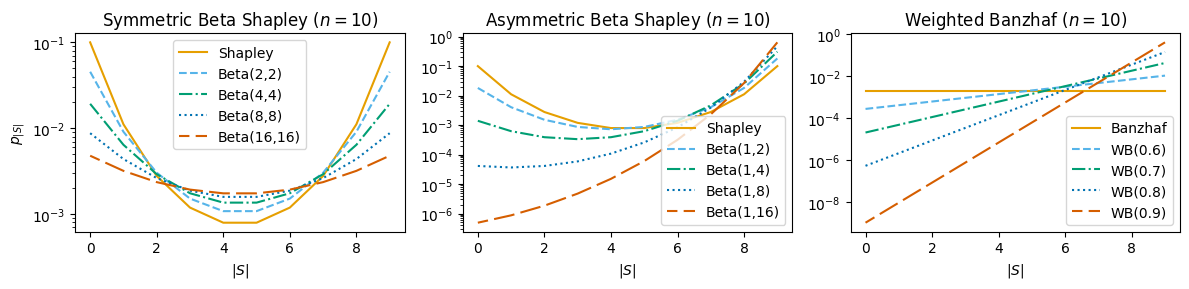

In [7]:
figsize = (12,3)
#plot_bn(ns=list(range(1,501)), figsize=figsize)
#plot_bn(ns=list(range(1,501, 1)), figsize=figsize, plot_sum=True)

plot_probabilistic_values(n=10, figsize=figsize)


/var/folders/qq/hk_0lt914qn6ny3hn40bvg3r0000gn/T/ipykernel_93165/4110466042.py:20: RuntimeWarning: invalid value encountered in sqrt
  b[ell+1] = np.sqrt(numerator / (denominator1 + denominator2))


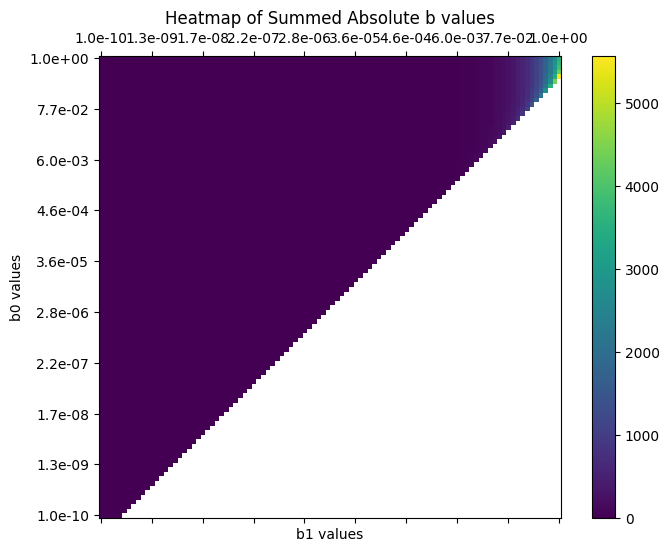

In [52]:
weighting_name = "weighted_banzhaf_0.9"
        
n = 10
p = get_p(n, weighting_name)

# try log increasing values of b0 and b1
val_ranges = np.geomspace(1e-10, 1, 100)
# all possible values of b0 and b1
b = np.zeros(n)
saved_b = np.zeros((len(val_ranges), len(val_ranges)))
# use meshgrid to get all possible values of b0 and b1
for b0_idx, b0 in enumerate(val_ranges):
    b[0] = b0
    for b1_idx, b1 in enumerate(val_ranges):
        b[1] = b1
        for ell in range(1, n-1):
            numerator = p[ell]**2 * b[ell]**2 * b[ell-1]**2
            denominator1 = 2 * p[ell] * p[ell-1] * b[ell-1]**2
            denominator2 = -1*p[ell-1]**2 * b[ell]**2
            b[ell+1] = np.sqrt(numerator / (denominator1 + denominator2))
        saved_b[b0_idx, b1_idx] = sum(np.abs(b))
        

# Plot the heatmap with labeled axes
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(saved_b, cmap='viridis', origin='lower')

# Set axis labels and ticks
ax.set_xticks(np.linspace(0, len(val_ranges) - 1, 10))
ax.set_yticks(np.linspace(0, len(val_ranges) - 1, 10))
ax.set_xticklabels([f"{val_ranges[int(i)]:.1e}" for i in np.linspace(0, len(val_ranges) - 1, 10)])
ax.set_yticklabels([f"{val_ranges[int(i)]:.1e}" for i in np.linspace(0, len(val_ranges) - 1, 10)])

plt.xlabel("b1 values")
plt.ylabel("b0 values")
plt.title("Heatmap of Summed Absolute b values")
fig.colorbar(cax)
plt.show()

In [56]:
for weighting in weightings:
    for weighting_name in weightings[weighting]:
        print(weighting_name)
        n = 10
        p = get_p(n, weighting_name)
        b = [1/np.sqrt(p[0]*p[1]),1/np.sqrt(p[0])]
        for ell in range(1, n):
            numerator = p[ell]**2 * b[ell-1]**2 * b[ell]**2
            denominator1 = 2 * p[ell] * p[ell-1] * b[ell-1]**2
            denominator2 = -1*p[ell-1]**2 * b[ell]**2
            b_ell_plus = np.sqrt(numerator / (denominator1 + denominator2))
            b.append(b_ell_plus)
        print(p)
        print(b)
        print()

shapley
[0.1        0.01111111 0.00277778 0.00119048 0.00079365 0.00079365
 0.00119048 0.00277778 0.01111111 0.1       ]
[30.0, 3.162277660168379, 0.7647191129018726, 0.287717668824218, 0.14576681287868154, 0.09365447359589484, 0.07433831385057747, 0.0724325022253941, 0.08765918661032059, 0.13715837605435166, 0.31302191288359354]

beta_shapley_2_2
[0.04545455 0.00909091 0.0030303  0.00151515 0.00108225 0.00108225
 0.00151515 0.0030303  0.00909091 0.04545455]
[49.193495504995376, 4.69041575982343, 1.5003875468350418, 0.6657502859356826, 0.3714436073992458, 0.25100551749382416, 0.20204618522194384, 0.1928197433193754, 0.21940945490699337, 0.30345076382145575, 0.5335298245804296]

beta_shapley_4_4
[0.01923077 0.00641026 0.00291375 0.00174825 0.00135975 0.00135975
 0.00174825 0.00291375 0.00641026 0.01923077]
[90.06664199358163, 7.21110255092798, 2.958176644740587, 1.5622449968822996, 0.9766686292899215, 0.7038698440143132, 0.5784574699037253, 0.5401233425508472, 0.5737774400871336, 0.6978